In [ ]:
from google.colab import drive # importa biblioteca que se conecta no google drive
drive.mount('/content/drive') # monta o google drive


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# importando as bibliotecas para manipulação de dados e criação de gráficos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split # biblioteca que separa dados de treino e teste
from sklearn.naive_bayes import GaussianNB # modelo usando o algoritmo de bayes
# bibliotecas que calcula as métricas do modelo:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [ ]:
input_file = '/content/drive/MyDrive/dados_usinagem_cnc.csv'

df_parts = pd.read_csv(input_file) # importa o arquivo csv do google drive

print('Amostra dos dados importados:')
display(df_parts.head()) # mostra as primeiras linhas do csv importado como dataframe

Amostra dos dados importados:


,Diametro_mm,Peso_g,Status
0,50.272,305.02,0
1,50.491,301.12,0
2,49.080,293.85,0
3,49.713,296.23,0
4,49.438,297.93,0


Text(0.5, 0, 'Peso (g)')

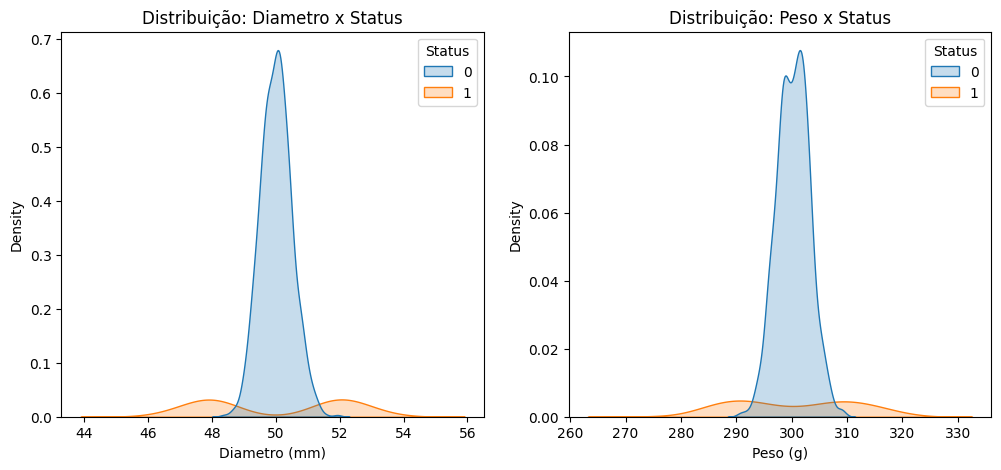

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

sns.kdeplot(data=df_parts,x="Diametro_mm",hue="Status",fill=True, ax=axes[0])

axes[0].set_title('Distribuição: Diametro x Status')
axes[0].set_xlabel('Diametro (mm)')

sns.kdeplot(data=df_parts,x="Peso_g",hue="Status",fill=True, ax=axes[1])

axes[1].set_title('Distribuição: Peso x Status')
axes[1].set_xlabel('Peso (g)')



In [ ]:
# separa as variáveis de input
X_data = df_parts[['Diametro_mm', 'Peso_g']]
# separa as variáveis de resultado (output)
y_data = df_parts['Status']


In [ ]:
# separa uma parcela dos dados para treino e outro para teste (20% dos dados para teste)
X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.2, random_state=42,
                                                    stratify=y_data)


In [ ]:
# cria o modelo e treina
model_bayes = GaussianNB()

model_bayes.fit(X_train, y_train)

GaussianNB()

In [ ]:
y_pred = model_bayes.predict(X_test) # faz a predição dos dados de teste
accuracy = accuracy_score(y_test, y_pred) # calcula a acurácia do modelo
print(f'Acurácia do modelo: {accuracy:.2f}')

Acurácia do modelo: 0.99


Text(0.5, 14.722222222222216, 'Previsão')

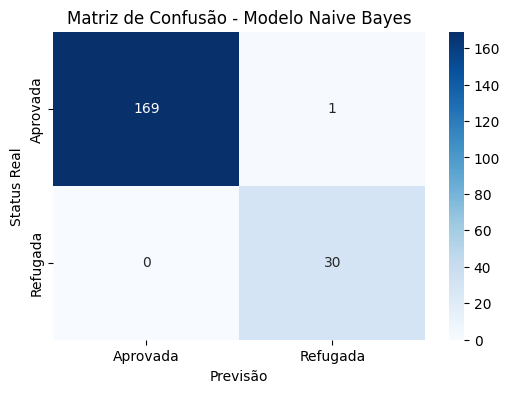

In [ ]:
matrix = confusion_matrix(y_test, y_pred) # cria a matriz de confusão
plt.figure(figsize=(6,4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Aprovada','Refugada'],
            yticklabels=['Aprovada','Refugada'])
plt.title('Matriz de Confusão - Modelo Naive Bayes')
plt.ylabel('Status Real')
plt.xlabel('Previsão')
